# Instructions

In this notebook you have some problems to solve with Python coding. For each problem, explain your code with comments and explain how it works to solve the problem being addressed. You also **MUST** include the answers you get from running your code. These instructions may change as needed, so we suggest you **read these anew on each assignment**.

Collaboration is both allowed and encouraged! Using available resources from your peers is both wise and efficient. While you are welcome to work collaboratively with classmates, that means you can work together to solve problems together, not that one person does the work and others copy it. You are also welcome to use the internet as a resource to refresh your memory, clarify concepts, and help with short code snippets. In order to model good practice, you **MUST** cite your sources **at the time of assignment submission** (we will not accept citations sent after-the-fact), and you should not be copying large portions of code wholesale from any source: internet, human, artificial intelligence, or otherwise.

Things that are off limits:
 -    Soliciting (hey, what did you get for question X? Can you send me your code?) and/or copying code and/or answers from another person.
 -    Using sources appropriately but failing to cite them.
 -    Getting any AI, including ChatGPT, Gemini, or CoPilot to do your work for you.


You **may not** set random_state, seed, or other similar parameters manually for any library unless explicitly instructed. For numpy, you **must** use the old-style ``np.random.uniform``, ``np.random.normal``, and so on, rather than ``np.random.default_rng()`` variants.

Make sure you include **(YOUR NAME, SUBQUESTION)** (e.g. "Jane Smith, 2c") at the start of every code cell.

**You may only use libraries that were imported for you at the top.**

**Note: All plots should have x and y axis labels, and a title at minimum, plus a legend if multiple distinct elements are present.**

# Import Statements

In [1]:
# ImportBlock
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import math
import time
import copy
from matplotlib.patches import FancyArrowPatch
from IPython.display import display

# Problem 1: The Faulty Factory (Module 1) (25 Points)

A manufacturing plant produces widgets using three different machines: Machine A, Machine B, and Machine C. At the end of each day, a random quality inspector samples widgets off the production line to check for defects. Your job is to build a Bayesian Monte Carlo simulator to reason about the defect rates and about which machine produced a defective widget.

The following prior information is known:
1. Machine A produces 50% of all widgets, Machine B produces 30%, and Machine C produces 20%.
2. The defect rates are:
    - Machine A: 2%
    - Machine B: 5%
    - Machine C: 10%
3. The inspector uses an imperfect detector: if a widget is truly defective, it flags it as defective with probability 90%. If a widget is fine, it still flags it as defective with probability of 8%.

Keep these constants at the top of your first code cell and reference them throughout.

## 1a: Bayesian Inference via Monte Carlo (10 Points)

Using a Monte Carlo simulation, simulate a production run of 1_000_000 widgets and answer the following questions by counting outcomes in the simulation, not by computing the analytical answer directly.

Your simulation should:
1. Determine whether each widget is truly defective based on the per-machine defect rates.
2. Use the detector probabilities to create a defectiveness flag for each widget.

Using your simulation, compute and print the following in the exact format below (probabilities are out of 1, not 100):
```py
>>> P(flagged) = 0.XXXX
>>> P(defective | flagged) = 0.XXXX
>>> P(Machine A | flagged & defective) = 0.XXXX
>>> P(Machine B | flagged & defective) = 0.XXXX
>>> P(Machine C | flagged & defective) = 0.XXXX
```

You should use a numpy structured approach (arrays over loops wherever possible) for efficiency.

The function definition should match:
```py
def run_factory_sim(n_widgets=1_000_000):
    #Returns a dict with keys: 'machine', 'defective', 'flagged'
    #Each value is a numpy array of length n_widgets
    pass
```

In [20]:
# Production probabilities for each machine
MACHINES = np.array(['A', 'B', 'C'])
PRODUCTION_RATES = np.array([0.50, 0.30, 0.20])

# Defect probabilities for each machine
DEFECT_RATES = np.array([0.02, 0.05, 0.10])

# Detector probabilities
P_FLAG_IF_DEFECTIVE = 0.90
P_FLAG_IF_FINE = 0.08


def run_factory_sim(n_widgets=1_000_000):
    """
    Simulate widget production, defects, and detector flags.

    Returns a dictionary containing three NumPy arrays:
    'machine', 'defective', and 'flagged'.
    """

    # Step 1: Randomly assign each widget to a machine
    machine = np.random.choice(
        MACHINES,
        size=n_widgets,
        p=PRODUCTION_RATES
    )

    # Step 2: Determine whether each widget is defective
    # Match each widget's machine to its defect probability
    machine_indices = np.searchsorted(MACHINES, machine) # converts machine labels ('A', 'B', 'C') into numerical indices (0, 1, 2)
    defect_probabilities = DEFECT_RATES[machine_indices]

    defective = np.random.random(n_widgets) < defect_probabilities

    # Step 3: Simulate the imperfect detector
    # Defective widgets have a 90% chance of being flagged
    # Fine widgets have an 8% chance of being flagged
    flag_probabilities = np.where(
        defective,
        P_FLAG_IF_DEFECTIVE,
        P_FLAG_IF_FINE
    ) # element-wise conditional selection

    flagged = np.random.random(n_widgets) < flag_probabilities

    # Return simulation results
    return {
        'machine': machine,
        'defective': defective,
        'flagged': flagged
    }

# Run the Monte Carlo simulation
results = run_factory_sim(1_000_000)

# Extract simulation arrays
machine = results['machine']
defective = results['defective']
flagged = results['flagged']

# Identify widgets that are both flagged and truly defective
flagged_and_defective = flagged & defective

# Calculate probabilities by counting simulated outcomes
p_flagged = np.mean(flagged)

p_defective_given_flagged = (
    np.sum(flagged_and_defective) / np.sum(flagged)
)

# Print results in the required format
print(f">>> P(flagged) = {p_flagged:.4f}")
print(f">>> P(defective | flagged) = {p_defective_given_flagged:.4f}")

# Calculate conditional probability for each machine
for m in MACHINES:
    p_machine = (
        np.sum((machine == m) & flagged_and_defective)
        / np.sum(flagged_and_defective)
    )

    print(f">>> P(Machine {m} | flagged & defective) = {p_machine:.4f}")

>>> P(flagged) = 0.1163
>>> P(defective | flagged) = 0.3444
>>> P(Machine A | flagged & defective) = 0.2195
>>> P(Machine B | flagged & defective) = 0.3334
>>> P(Machine C | flagged & defective) = 0.4471



### Monte Carlo Simulation: Factory Defects and Detector Flags

**Goal:** Simulate 1,000,000 widgets to estimate the probability of being flagged, the probability that a flagged widget is truly defective, and the probability that a flagged defective widget came from each machine.

**Step 1: Randomly assign widgets to machines.**

Use `np.random.choice()` to assign each widget to Machine A, B, or C according to their production probabilities:

$$
P(A)=0.50,\quad P(B)=0.30,\quad P(C)=0.20
$$

**Step 2: Simulate whether each widget is defective.**

Each machine has a different defect rate:

$$
P(D\mid A)=0.02,\quad P(D\mid B)=0.05,\quad P(D\mid C)=0.10
$$

- `np.searchsorted()` converts machine labels (`A`, `B`, `C`) into indices (`0`, `1`, `2`).
- `DEFECT_RATES[machine_indices]` assigns the corresponding defect probability to each widget.
- `np.random.random(n_widgets) < defect_probabilities` generates a Boolean array indicating whether each widget is defective.

**Step 3: Simulate the imperfect detector.**

The detector has two possible behaviors:

- **True positive:** A defective widget is flagged with probability 0.90.
- **False positive:** A nondefective widget is flagged with probability 0.08.

Use `np.where()` to assign the appropriate flag probability based on each widget's actual defect status:

```python
flag_probabilities = np.where(
    defective,
    P_FLAG_IF_DEFECTIVE,
    P_FLAG_IF_FINE
)
```

Then generate random flags using `np.random.random()`.

**Step 4: Estimate probabilities by counting outcomes.**

NumPy Boolean arrays allow us to count events efficiently:

- `np.mean(flagged)` calculates the proportion of all widgets that are flagged.
- `flagged & defective` identifies widgets that are both flagged and truly defective.
- `np.sum(condition)` counts the number of `True` values.

The conditional probabilities are estimated as:

$$
P(D\mid F)\approx
\frac{\text{Number of flagged and defective widgets}}
{\text{Number of flagged widgets}}
$$

$$
P(M_i\mid F,D)\approx
\frac{\text{Number of flagged defective widgets from machine }i}
{\text{Total number of flagged defective widgets}}
$$

**Key takeaway:** Monte Carlo simulation estimates probabilities by generating random outcomes according to known distributions and counting the resulting events. NumPy vectorization allows us to simulate 1,000,000 widgets efficiently without explicit loops over individual widgets. As the number of simulated widgets increases, the estimates generally approach their theoretical probabilities.


## 1b: Analytical Verification (5 Points)

Now compute the exact analytical answers for the same quantities using the Law of Total Probability and Bayes' Theorem (round to 4 decimal places).

Print the analytical results in the same format as 1a, and also print the absolute difference between your Monte Carlo estimate and the analytical result for each quantity:
```py
>>> [Analytical] P(flagged) = 0.XXXX
>>> [Analytical] P(defective | flagged) = 0.XXXX
>>> [Analytical] P(Machine A | flagged & defective) = 0.XXXX
>>> ...
>>> Max absolute error vs. Monte Carlo: X.XXXX
```

Briefly explain in a markdown cell below your code the steps you took to apply Bayes' Theorem analytically (i.e. show your work).

In [4]:
# Step 1: Calculate the overall probability of a true defect
# Law of Total Probability
p_defective = np.sum(PRODUCTION_RATES * DEFECT_RATES)

# Step 2: Calculate the probability of being flagged
p_flagged_exact = (
    P_FLAG_IF_DEFECTIVE * p_defective
    + P_FLAG_IF_FINE * (1 - p_defective)
)

# Step 3: Apply Bayes' Theorem
p_defective_given_flagged_exact = (
    P_FLAG_IF_DEFECTIVE * p_defective / p_flagged_exact
)

# Step 4: Calculate the machine probabilities given flagged and defective
p_machine_exact = (
    PRODUCTION_RATES * DEFECT_RATES * P_FLAG_IF_DEFECTIVE
    / (p_defective * P_FLAG_IF_DEFECTIVE)
)

# Store analytical results
analytical = np.concatenate((
    [p_flagged_exact, p_defective_given_flagged_exact],
    p_machine_exact
))

# Step 5: Calculate the corresponding Monte Carlo estimates
monte_carlo = np.array([
    np.mean(flagged),
    np.mean(defective[flagged]),
    *[
        np.mean(machine[flagged_and_defective] == m)
        for m in MACHINES
    ]
])

# Print analytical results and absolute differences
labels = [
    "P(flagged)",
    "P(defective | flagged)",
    *[f"P(Machine {m} | flagged & defective)" for m in MACHINES]
]

for label, exact, estimate in zip(labels, analytical, monte_carlo):
    print(f">>> [Analytical] {label} = {exact:.4f}")
    print(f"    Absolute difference = {abs(exact - estimate):.4f}")

print(f">>> Max absolute error vs. Monte Carlo: {np.max(np.abs(analytical - monte_carlo)):.4f}")


>>> [Analytical] P(flagged) = 0.1169
    Absolute difference = 0.0005
>>> [Analytical] P(defective | flagged) = 0.3464
    Absolute difference = 0.0010
>>> [Analytical] P(Machine A | flagged & defective) = 0.2222
    Absolute difference = 0.0005
>>> [Analytical] P(Machine B | flagged & defective) = 0.3333
    Absolute difference = 0.0006
>>> [Analytical] P(Machine C | flagged & defective) = 0.4444
    Absolute difference = 0.0011
>>> Max absolute error vs. Monte Carlo: 0.0011



### Analytical Solution Using Bayes' Theorem

**Step 1: Calculate the overall defect probability using the Law of Total Probability.**

$$
P(D) = \sum_{i\in\{A,B,C\}} P(M_i)P(D\mid M_i)
$$

$$
= 0.5(0.02)+0.3(0.05)+0.2(0.10)=0.045
$$

**Step 2: Calculate the probability that a widget is flagged.**

Let $F$ denote a flagged widget and $D$ denote a truly defective widget.

$$
P(F)=P(F\mid D)P(D)+P(F\mid \neg D)P(\neg D)
$$

$$
=0.9(0.045)+0.08(0.955)=\boxed{0.1169}
$$

**Step 3: Apply Bayes' Theorem to calculate the probability that a flagged widget is truly defective.**

$$
P(D\mid F)=\frac{P(F\mid D)P(D)}{P(F)}
$$

$$
=\frac{0.9(0.045)}{0.1169}=\boxed{0.3464}
$$

**Step 4: Calculate the probability of each machine given that a widget is both flagged and defective.**

Using Bayes' Theorem and assuming the detector's sensitivity is the same for all machines:

$$
P(M_i\mid F,D)
=\frac{P(F\mid D,M_i)P(D\mid M_i)P(M_i)}{P(F,D)}
$$

Since $P(F\mid D,M_i)=0.9$ for every machine, the detector probability cancels:

$$
P(M_i\mid F,D)=\frac{P(D\mid M_i)P(M_i)}{P(D)}
$$

Therefore:

$$
P(A\mid F,D)=\frac{0.02(0.50)}{0.045}=\boxed{0.2222}
$$

$$
P(B\mid F,D)=\frac{0.05(0.30)}{0.045}=\boxed{0.3333}
$$

$$
P(C\mid F,D)=\frac{0.10(0.20)}{0.045}=\boxed{0.4444}
$$

**Interpretation:** The analytical results provide exact reference values for evaluating the Monte Carlo estimates. As the number of simulated widgets increases, the Monte Carlo estimates should generally approach these analytical probabilities.


## 1c: Sequential Bayesian Updating (10 Points)

The inspector now observes widgets one at a time and wants to continuously update their belief about which machine is currently running (you may assume only one machine runs at a time, but the inspector doesn't know which one).

Code a class `BayesUpdater` that maintains a posterior distribution over the three machines and updates it each time a new widget observation (flagged or not flagged) comes in.

```py
class BayesUpdater:
    #MACHINE_PROBS holds prior information 1 and 2 from the question intro
    def __init__(self, prior=MACHINE_PROBS):
        #Store prior as current posterior
        #self.posterior
        pass

    def update(self, flagged):
        #Update the posterior using Bayes' theorem given a new observation
        #flagged=True means the inspector flagged the widget, flagged=False means it was clean
        #self.posterior
        pass

    def reset(self, prior=MACHINE_PROBS):
        #Reset the posterior back to the prior
        pass
```

Once implemented:
1. Simulate 3 separate runs, each of 200 widget observations, where the true machine is A, B, and C respectively.
2. For each run, plot the evolution of `P(Machine A)`, `P(Machine B)`, and `P(Machine C)` across all 200 steps on a single figure with 3 subplots (one per true machine). Y-limits should be [0, 1].
3. Print the final posterior for each run in the form:
```py
>>> [True=A] Final Posterior: A=0.XXXX  B=0.XXXX  C=0.XXXX
>>> [True=B] Final Posterior: A=0.XXXX  B=0.XXXX  C=0.XXXX
>>> [True=C] Final Posterior: A=0.XXXX  B=0.XXXX  C=0.XXXX
```

Please use the following plotting code:
```py
N_OBS = 200
labels = ['A', 'B', 'C']
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, axes = plt.subplots(1, 3, figsize=(16,4), sharey=True)

for col, true_m in enumerate([0, 1, 2]):
    updater = BayesUpdater()
    history = [updater.posterior.copy()]
    p_flag_true = FLAG_LIKELIHOODS[true_m]
    for _ in range(N_OBS):
        updater.update(np.random.uniform()<p_flag_true)
        history.append(updater.posterior.copy())
    history = np.array(history)

    ax = axes[col]
    for k, (lbl, clr) in enumerate(zip(labels, colors)):
        ax.plot(history[:,k], label=f'P(Machine {lbl})', color=clr, linewidth=1.5)
    ax.axhline(1, color=colors[true_m], linestyle='--', alpha=0.4, linewidth=1)
    ax.set_title(f'True Machine: {labels[true_m]}')
    ax.set_xlabel('Observation Step')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
    if col == 0:
        ax.set_ylabel('Posterior Probability')

fig.suptitle('Sequential Bayesian Updating of Machine Posterior', fontsize=13)
plt.tight_layout()
plt.show()

for true_m in [0, 1, 2]:
    updater = BayesUpdater()
    for _ in range(N_OBS):
        updater.update(np.random.uniform() < FLAG_LIKELIHOODS[true_m])
    fp = updater.posterior
    print(f"[True={labels[true_m]}] Final Posterior: A={fp[0]:.4f}  B={fp[1]:.4f}  C={fp[2]:.4f}")
```

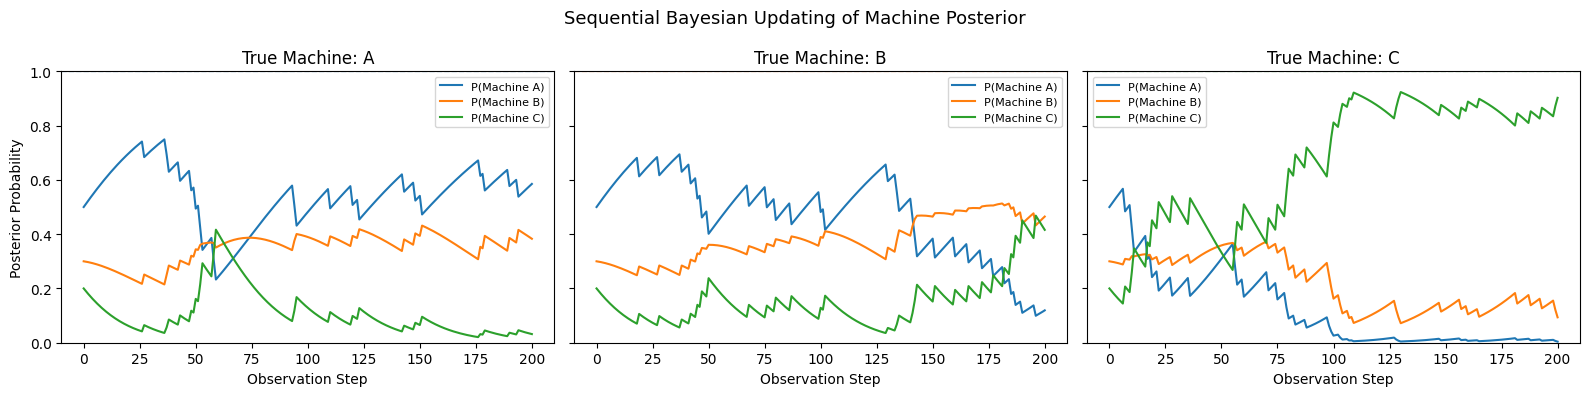

>>> [True=A] Final Posterior: A=0.5851  B=0.3830  C=0.0318
>>> [True=B] Final Posterior: A=0.1192  B=0.4648  C=0.4159
>>> [True=C] Final Posterior: A=0.0040  B=0.0936  C=0.9023


In [5]:
# Prior probabilities of the three machines
MACHINE_PROBS = np.array([0.50, 0.30, 0.20])

# Probability of a flag for each machine
# P(F|M) = P(F|D)P(D|M) + P(F|not D)P(not D|M)
FLAG_LIKELIHOODS = (
    P_FLAG_IF_DEFECTIVE * DEFECT_RATES
    + P_FLAG_IF_FINE * (1 - DEFECT_RATES)
)


class BayesUpdater:
    def __init__(self, prior=MACHINE_PROBS):
        # Store the initial prior as the current posterior
        self.posterior = np.array(prior, dtype=float).copy()
        self.posterior /= self.posterior.sum()

    def update(self, flagged):
        # Select likelihoods based on the observation
        if flagged:
            likelihoods = FLAG_LIKELIHOODS
        else:
            likelihoods = 1 - FLAG_LIKELIHOODS

        # Apply Bayes' theorem: posterior proportional to prior * likelihood
        self.posterior *= likelihoods

        # Normalize so the probabilities sum to 1
        self.posterior /= self.posterior.sum()

    def reset(self, prior=MACHINE_PROBS):
        # Reset the posterior to the specified prior
        self.posterior = np.array(prior, dtype=float).copy()
        self.posterior /= self.posterior.sum()

N_OBS = 200
labels = ['A', 'B', 'C']
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

final_posteriors = []

for col, true_m in enumerate([0, 1, 2]):
    updater = BayesUpdater()
    history = [updater.posterior.copy()]
    p_flag_true = FLAG_LIKELIHOODS[true_m]

    for _ in range(N_OBS):
        updater.update(np.random.uniform() < p_flag_true)
        history.append(updater.posterior.copy())

    history = np.array(history)
    final_posteriors.append(updater.posterior.copy())

    ax = axes[col]
    for k, (lbl, clr) in enumerate(zip(labels, colors)):
        ax.plot(history[:, k], label=f'P(Machine {lbl})',
                color=clr, linewidth=1.5)

    ax.axhline(1, color=colors[true_m],
               linestyle='--', alpha=0.4, linewidth=1)

    ax.set_title(f'True Machine: {labels[true_m]}')
    ax.set_xlabel('Observation Step')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)

    if col == 0:
        ax.set_ylabel('Posterior Probability')

fig.suptitle('Sequential Bayesian Updating of Machine Posterior', fontsize=13)
plt.tight_layout()
plt.show()

# Print final posteriors from the plotted simulations
for true_m, fp in enumerate(final_posteriors):
    print(f">>> [True={labels[true_m]}] Final Posterior: "
          f"A={fp[0]:.4f}  B={fp[1]:.4f}  C={fp[2]:.4f}")


### Sequential Bayesian Updating

For each machine $M_i$, we first calculate the probability of a flagged observation using the Law of Total Probability:

$$
P(F\mid M_i)
=P(F\mid D)P(D\mid M_i)
+P(F\mid \neg D)P(\neg D\mid M_i)
$$

This gives:

$$
P(F\mid A)=0.0964,\quad
P(F\mid B)=0.1210,\quad
P(F\mid C)=0.1620
$$

For each new observation $O_t$ (flagged or not flagged), we apply Bayes' Theorem:

$$
P(M_i\mid O_{1:t})=
\frac{
P(O_t\mid M_i)P(M_i\mid O_{1:t-1})
}{
\sum_j P(O_t\mid M_j)P(M_j\mid O_{1:t-1})
}
$$

The posterior from the previous step becomes the prior for the next step. We repeat this process for 200 observations, assuming the same machine produces every widget in a given run and observations are conditionally independent.

**Interpretation:** As more observations are collected, the posterior should generally favor the true machine because each machine has a different probability of producing flagged widgets. However, convergence may be slow because the flag probabilities are relatively similar, and 200 observations may not always provide enough evidence to identify the correct machine confidently.


# Problem 2: Lost in the Warehouse! (Module 2) (35 Points)

A robot is navigating a warehouse represented as an NxM grid. The robot starts at the top-left corner and needs to reach a goal located at the bottom-right corner. Some cells contain obstacles the robot cannot enter.

Grid rules:
- (0, 0) is the top-left cell, (N-1, M-1) is the bottom-right (goal).
- The robot can move in four directions: Up (0), Down (1), Left (2), Right (3).
- Moving into a wall or obstacle keeps the robot in its current cell and costs -5.
- Each step costs -1 reward. Reaching the goal gives a reward of +100 and ends the episode.
- If the robot has not reached the goal in max_steps, the episode ends with no bonus.

Below is a provided `.render()` method to visualize the grid:
```py
def render(self, policy=None, ax=None):
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(self.M * 0.9, self.N * 0.9))
    grid_display = np.zeros((self.N, self.M))
    for (r,c) in self.obstacles:
        grid_display[r,c] = 1
    grid_display[self.N-1, self.M-1] = 0
    grid_display[self.agent_pos[0], self.agent_pos[1]] = 0
    ax.imshow(grid_display, cmap='binary', vmin=0, vmax=1)
    ax.scatter([self.M-1], [self.N-1], s=2900, marker='s', c='green', linewidths=2)
    ax.scatter([self.agent_pos[1]], [self.agent_pos[0]], s=2900, marker='s', c='red', linewidths=2)
    ax.imshow(grid_display, cmap='binary', vmin=-1, vmax=3)
    ax.set_xticks(range(self.M))
    ax.set_yticks(range(self.N))
    ax.set_xlabel('Column')
    ax.set_ylabel('Row')
    ax.set_title(f'Warehouse Grid  |  Step: {self.step_count}')
    arrows = {0: (0, -0.35), 1: (0, 0.35), 2: (-0.35, 0), 3: (0.35, 0)}
    if policy is not None:
        for r in range(self.N):
            for c in range(self.M):
                if (r, c) not in self.obstacles and (r, c) != (self.N-1, self.M-1):
                    a = policy[r, c]
                    dx, dy = arrows[a]
                    ax.annotate('', xy=(c+dx, r+dy), xytext=(c, r),
                                arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
    if show:
        plt.tight_layout()
        plt.show()
        return fig, ax
```

## 2a: Warehouse Environment (10 Points)

Code a class for the warehouse environment described above. You need to align your class with the blueprint below:

```py
class WarehouseEnv:
    def __init__(self, N=6, M=6, obstacle_density=0.1):
        self.N, self.M = N, M
        all_cells = [(r,c) for r in range(N) for c in range(M) if (r,c) not in [(0,0),(N-1,M-1)]]
        n_obs = int(len(all_cells)*obstacle_density)
        chosen = np.random.choice(len(all_cells), size=n_obs, replace=False)
        self.obstacles = set(all_cells[i] for i in chosen)
        self.__reset__()

    def __reset__(self):
        #Reset agent to (0, 0), reset step counter
        #self.agent_pos, self.step_count, self.done
        pass

    def step(self, action):
        #Compute next position given action (0=Up, 1=Down, 2=Left, 3=Right)
        #Clip/bounce off grid edges, don't enter obstacles
        #Calculate reward: +100 if goal reached, -5 if wall or obstacle hit, -1 otherwise
        #Update self.agent_pos, self.step_count, self.done
        #return next_state, reward, done
        pass

    def get_state(self):
        #Return the current state as a tuple (row, col)
        pass

    def render(self, policy=None, ax=None):
        #Place the render method above here
        pass
```

Once your class is implemented:
1. Create an instance with N=8, M=8, and obstacle_density=0.2. The default blueprint will have different default values for N, M, and density; keep those defaults and pass these values in over those.
2. Render the initial state.
3. Take 5 random actions and render the state after all 5 steps.

Initial state: (0, 0)


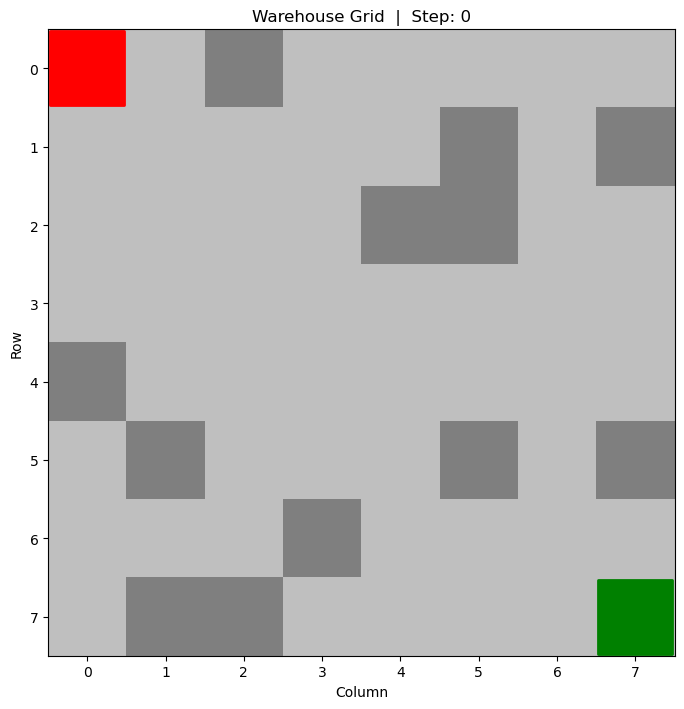

Step 1: Action=Down, State=(1, 0), Reward=-1
Step 2: Action=Left, State=(1, 0), Reward=-5
Step 3: Action=Up, State=(0, 0), Reward=-1
Step 4: Action=Right, State=(0, 1), Reward=-1
Step 5: Action=Left, State=(0, 0), Reward=-1


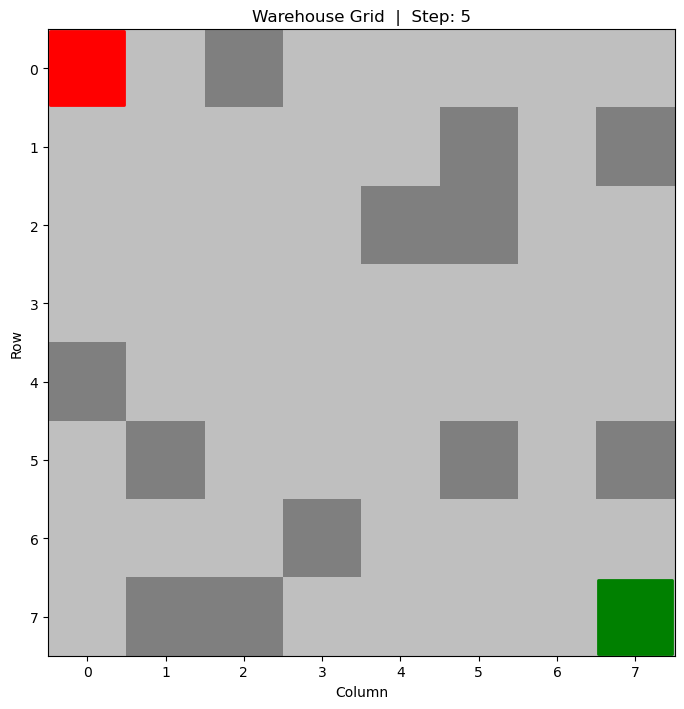

(<Figure size 720x720 with 1 Axes>,
 <Axes: title={'center': 'Warehouse Grid  |  Step: 5'}, xlabel='Column', ylabel='Row'>)

In [2]:
class WarehouseEnv:
    def __init__(self, N=6, M=6, obstacle_density=0.1):
        self.N, self.M = N, M
        self.max_steps=100

        # Randomly generate obstacles, excluding start and goal
        all_cells = [(r, c) for r in range(N) for c in range(M)
                     if (r, c) not in [(0, 0), (N-1, M-1)]]

        n_obs = int(len(all_cells) * obstacle_density)
        chosen = np.random.choice(len(all_cells), size=n_obs, replace=False)
        self.obstacles = set(all_cells[i] for i in chosen)

        self.__reset__()

    def __reset__(self):
        # Reset agent position, step counter, and episode status
        self.agent_pos = (0, 0)
        self.step_count = 0
        self.done = False

        return self.get_state()

    def step(self, action):
        # Do not allow actions after the episode ends
        if self.done:
            return self.get_state(), 0, True

        # Define movement directions: Up, Down, Left, Right
        moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]

        # Calculate the proposed next position
        dr, dc = moves[action]
        r, c = self.agent_pos
        next_pos = (r + dr, c + dc)

        # Check whether the next position is invalid
        if (not (0 <= next_pos[0] < self.N and
                 0 <= next_pos[1] < self.M)
                or next_pos in self.obstacles):

            # Stay in place and receive a penalty
            reward = -5

        else:
            # Move to the valid next position
            self.agent_pos = next_pos

            # Check whether the goal is reached
            if self.agent_pos == (self.N-1, self.M-1):
                reward = 100
                self.done = True
            else:
                reward = -1

        # Update the step counter
        self.step_count += 1
        if self.step_count >= self.max_steps:
            self.done = True

        return self.get_state(), reward, self.done

    def get_state(self):
        # Return the current position as a tuple
        return self.agent_pos

    def render(self, policy=None, ax=None):
        show = ax is None
        if show:
            fig, ax = plt.subplots(figsize=(self.M * 0.9, self.N * 0.9))
        grid_display = np.zeros((self.N, self.M))
        for (r,c) in self.obstacles:
            grid_display[r,c] = 1
        grid_display[self.N-1, self.M-1] = 0
        grid_display[self.agent_pos[0], self.agent_pos[1]] = 0
        ax.imshow(grid_display, cmap='binary', vmin=0, vmax=1)
        ax.scatter([self.M-1], [self.N-1], s=2900, marker='s', c='green', linewidths=2)
        ax.scatter([self.agent_pos[1]], [self.agent_pos[0]], s=2900, marker='s', c='red', linewidths=2)
        ax.imshow(grid_display, cmap='binary', vmin=-1, vmax=3)
        ax.set_xticks(range(self.M))
        ax.set_yticks(range(self.N))
        ax.set_xlabel('Column')
        ax.set_ylabel('Row')
        ax.set_title(f'Warehouse Grid  |  Step: {self.step_count}')
        arrows = {0: (0, -0.35), 1: (0, 0.35), 2: (-0.35, 0), 3: (0.35, 0)}
        if policy is not None:
            for r in range(self.N):
                for c in range(self.M):
                    if (r, c) not in self.obstacles and (r, c) != (self.N-1, self.M-1):
                        a = policy[r, c]
                        dx, dy = arrows[a]
                        ax.annotate('', xy=(c+dx, r+dy), xytext=(c, r),
                                    arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
        if show:
            plt.tight_layout()
            plt.show()
            return fig, ax


# Create an 8x8 warehouse with 20% obstacle density
env = WarehouseEnv(N=8, M=8, obstacle_density=0.2)

# Display the initial state
print("Initial state:", env.get_state())
env.render()

# Define action names for readability
action_names = ['Up', 'Down', 'Left', 'Right']

# Take 5 random actions
for i in range(5):
    action = np.random.randint(0, 4)

    next_state, reward, done = env.step(action)

    print(f"Step {i+1}: Action={action_names[action]}, "
          f"State={next_state}, Reward={reward}")

    if done:
        break

# Display the warehouse after the actions
env.render()

### <font color='blue' size=5pt>Warehouse Environment: Logic and Key Components</font>

The `WarehouseEnv` class creates a **grid-based reinforcement learning environment** where an agent learns to navigate from a starting position to a goal while avoiding obstacles.

#### 1. Environment Setup (`__init__`)

- **Grid:** An $N \times M$ warehouse (default: $6 \times 6$).
- **Start:** Top-left corner $(0,0)$.
- **Goal:** Bottom-right corner $(N-1,M-1)$.
- **Obstacles:** Randomly placed according to `obstacle_density`, excluding the start and goal.
- **Maximum steps:** 100 actions per episode.

**Key point:** Obstacles are generated when the environment is created and remain fixed during subsequent resets.

#### 2. State and Actions

The **state** is the agent's current position:

$$
s=(r,c)
$$

The agent can choose from **four discrete actions**:

| Action | Index | Position Change |
|:--|:--:|:--|
| Up | 0 | $(-1,0)$ |
| Down | 1 | $(1,0)$ |
| Left | 2 | $(0,-1)$ |
| Right | 3 | $(0,1)$ |

**Key point:** The agent observes its current position, but the state does not explicitly include obstacle locations.

#### 3. State Transitions and Rewards (`step`)

Each action attempts to move the agent to a neighboring cell.

| Condition | State Transition | Reward |
|:--|:--|:--:|
| Valid move | Move to next cell | $-1$ |
| Obstacle or boundary | Stay in place | $-5$ |
| Reach the goal | Move to goal; end episode | $+100$ |

**Key points:**
- The **step penalty ($-1$)** encourages shorter paths.
- The **collision penalty ($-5$)** discourages invalid moves.
- The **goal reward ($+100$)** encourages successful navigation.
- An episode ends when the agent reaches the goal or takes 100 steps.

#### 4. Environment Interaction

The environment follows a standard reinforcement learning interaction cycle:

$$
\boxed{
s_t \xrightarrow{\text{Choose }a_t}
\texttt{env.step}(a_t)
\longrightarrow (s_{t+1},r_t,\text{done})
}
$$

- `__reset__()`: Restarts the episode at $(0,0)$.
- `get_state()`: Returns the current position.
- `step(action)`: Executes an action and returns the next state, reward, and termination status.
- `render(policy=None)`: Visualizes the grid, obstacles, agent, goal, and optionally policy arrows.

#### 5. Example: Random Agent

The example creates an **$8\times8$ warehouse with 20% obstacle density** and executes up to five random actions:

```python
action = np.random.randint(0, 4)
next_state, reward, done = env.step(action)
```

**Key point:** The agent currently selects actions **randomly**, without learning from rewards. 

## 2b: State-Action Space Analysis (5 Points)

Code a function to compute the total number of valid states and the size of the Q-table for an NxM grid with a given set of obstacles.

```py
def QTableDimCalc(N=8, M=8, obstacles=set(), n_actions=4):
    #valid_states: all (row, col) pairs that are not obstacles
    #q_table_size: valid_states * n_actions
    return valid_states, q_table_size
```

Print the results for your 8x8 grid instance from 2a in the form:
```py
>>> Valid States: XXX
>>> Q-Table Size: XXXX
```

In a markdown cell, briefly explain what each dimension of the Q-table represents and why we exclude obstacle cells.

In [3]:
def QTableDimCalc(N=8, M=8, obstacles=set(), n_actions=4):
    # Count all grid cells excluding obstacles
    valid_states = N * M - len(obstacles)

    # Each valid state has n_actions possible actions
    q_table_size = valid_states * n_actions

    return valid_states, q_table_size


# Calculate dimensions for the warehouse created in 2a
valid_states, q_table_size = QTableDimCalc(
    N=env.N,
    M=env.M,
    obstacles=env.obstacles
)

print(f">>> Valid States: {valid_states}")
print(f">>> Q-Table Size: {q_table_size}")


>>> Valid States: 52
>>> Q-Table Size: 208



### Q-Table Dimensions

A Q-table stores the expected cumulative reward $Q(s,a)$ for taking action $a$ in state $s$ and following a policy afterward.

- **States (rows):** Each valid grid position $(r,c)$ represents a state. For our 8×8 grid, there are $64-12=52$ valid states.
- **Actions (columns):** Each state has 4 possible actions: Up, Down, Left, and Right.
- **Q-table size:** $52\times4=208$ entries, each storing a Q-value for a state-action pair.

We exclude obstacle cells because the robot cannot occupy them, so no Q-values need to be stored for those states. However, actions that attempt to enter obstacles still have Q-values because they can be selected from valid states and result in a penalty.


## 2c: Q-Learning Agent (12.5 Points)

Train a Q-learning agent on the warehouse environment. You must implement the standard Q-learning update rule:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

You need to align your function with the blueprint below:
```py
def train_qlearning(env, n_episodes=5_000, alpha=0.1, gamma=0.95, epsilon=0.1, max_steps=200):
    #Initialize Q-table as zeros: shape (N, M, n_actions)
    #self.Q

    #Training loop over episodes
        #Reset environment
        #Step loop (up to max_steps)
            #Epsilon-greedy action selection
            #Take action, observe next_state, reward, done
            #Q-learning update
            #Track episode reward
        #Store episode reward
    return Q, episode_rewards
```

Use n_episodes=5_000, alpha=0.1, gamma=0.95, an epsilon of 0.1, and max_steps=200.

After training:
1. Plot the smoothed episode reward over training (use a rolling window of 100 episodes). Add a horizontal dashed line at the reward for a perfect straight-line path (no obstacles) as a reference.
2. Extract the greedy policy (argmax over Q for each state) and render the grid with the learned policy arrows overlaid using `.render(policy=...)`.
3. Print the average reward over the last 500 episodes:
```py
>>> Avg Reward (last 500 eps): XX.XX
```

Feel free to consult the following plotting code:
```py
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(smoothed, label='Smoothed Reward (window=100)')
ax.axhline(perfect_reward, color='green', linestyle='--', label=f'Perfect Path ({perfect_reward})')
ax.set_xlabel('Episode')
ax.set_ylabel('Total Reward')
ax.set_title('Q-Learning Training Curve')
ax.legend()
plt.tight_layout()
plt.show()

policy = np.argmax(Q, axis=2)
env.__reset__()
env.render(policy=policy)

print(f"Avg Reward (last 500 eps): {np.mean(episode_rewards[-500:]):.2f}")
```

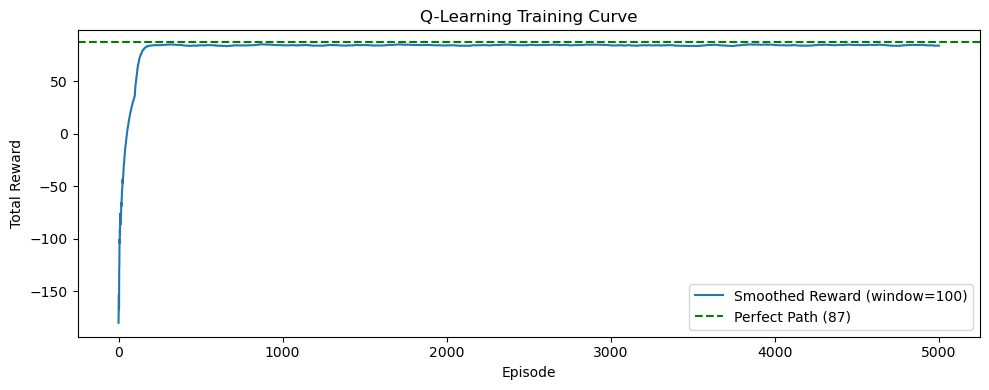

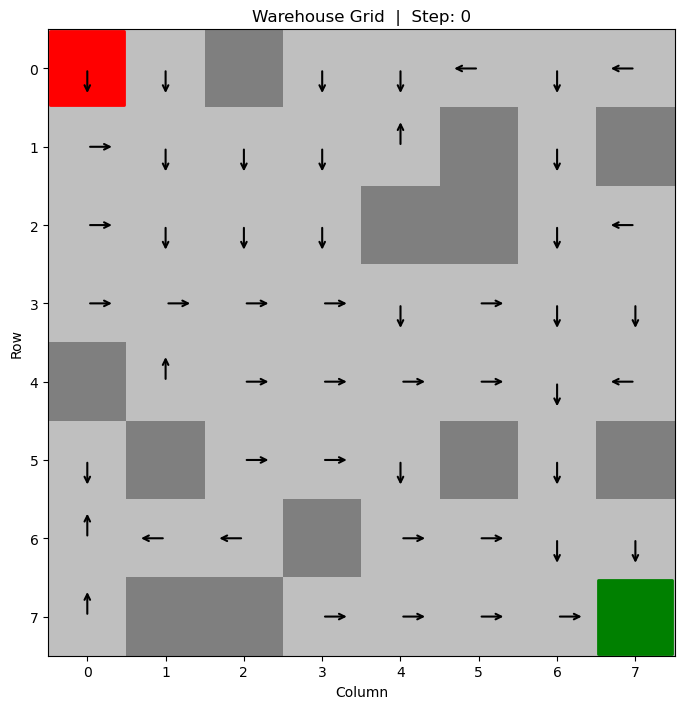

>>> Avg Reward (last 500 eps): 84.36


In [4]:
def train_qlearning(env, n_episodes=5_000, alpha=0.1,
                    gamma=0.95, epsilon=0.1, max_steps=200):

    # Initialize Q-table: rows x columns x actions
    Q = np.zeros((env.N, env.M, 4))

    # Store total reward for each episode
    episode_rewards = []

    # Training loop
    for episode in range(n_episodes):

        # Reset environment at the start of each episode
        state = env.__reset__()
        total_reward = 0

        # Run up to max_steps actions per episode
        for step in range(max_steps):

            # Epsilon-greedy action selection
            if np.random.random() < epsilon:
                action = np.random.randint(4)  # Explore
            else:
                action = np.argmax(Q[state])    # Exploit

            # Take action and observe result
            next_state, reward, done = env.step(action)

            # Q-learning update
            # No future reward after reaching the terminal state
            if done:
                target = reward
            else:
                target = reward + gamma * np.max(Q[next_state])

            Q[state][action] += alpha * (target - Q[state][action])

            # Track episode reward
            total_reward += reward

            # Move to next state
            state = next_state

            # Stop if the goal is reached
            if done:
                break

        # Store total reward for this episode
        episode_rewards.append(total_reward)

    return Q, episode_rewards

# Train Q-learning on the existing warehouse
Q, episode_rewards = train_qlearning(
    env,
    n_episodes=5_000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
)

# Smooth rewards using a rolling average of 100 episodes
smoothed = pd.Series(episode_rewards).rolling(
    window=100, min_periods=1
).mean()

# Calculate reward for a perfect path without obstacles
min_steps = (env.N - 1) + (env.M - 1)
perfect_reward = 100 - (min_steps - 1)

# Plot training curve
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(smoothed, label='Smoothed Reward (window=100)')

ax.axhline(
    perfect_reward,
    color='green',
    linestyle='--',
    label=f'Perfect Path ({perfect_reward})'
)

ax.set_xlabel('Episode')
ax.set_ylabel('Total Reward')
ax.set_title('Q-Learning Training Curve')
ax.legend()

plt.tight_layout()
plt.show()

# Extract greedy policy: best action at each grid position
policy = np.argmax(Q, axis=2)

# Reset environment to the starting position
env.__reset__()

# Render the grid with learned policy arrows
env.render(policy=policy)

# Calculate average reward over the last 500 episodes
avg_reward = np.mean(episode_rewards[-500:])

print(f">>> Avg Reward (last 500 eps): {avg_reward:.2f}")


### Q-Learning Training

We train the robot using Q-learning, which learns the expected discounted cumulative reward for each state-action pair.

The Q-learning update rule is:

$$
Q(s,a)\leftarrow Q(s,a)+\alpha\left[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\right]
$$

where:
- $\alpha=0.1$: Learning rate, controlling how quickly Q-values are updated.
- $\gamma=0.95$: Discount factor, determining the importance of future rewards.
- $\epsilon=0.1$: Exploration probability, meaning the robot selects a random action 10% of the time.

The agent trains for 5,000 episodes, with a maximum of 200 steps per episode. Each episode begins at $(0,0)$ and ends when the robot reaches the goal or exceeds the step limit.

**Interpretation:** Initially, the robot explores randomly and often receives negative rewards from unnecessary moves or collisions. As training progresses, the Q-values improve, and the robot learns a policy that favors shorter paths to the goal. The smoothed reward curve should generally increase and stabilize as the agent learns. However, because epsilon remains at 0.1, the agent continues exploring during training, so its average reward may remain below the perfect-path reference.


## 2d: Optimal vs. Random Baseline (7.5 Points)

To understand how well your agent learned, compare it to a random policy baseline.

Make a function `evaluate_policy(env, Q=None, n_eval=1_000, max_steps=200)` that:
- If `Q` is provided, acts greedily with respect to Q.
- If `Q=None`, acts completely randomly.
- Returns the mean and standard deviation of the total episode reward across `n_eval` episodes.

Run this function for both the trained Q-table and for a random policy, and print the results in this format:
```py
>>> [Trained]  Mean Reward: XX.XX  |  Std: XX.XX
>>> [Random]  Mean Reward: XX.XX  |  Std: XX.XX
```

In [9]:
def evaluate_policy(env, Q=None, n_eval=1_000, max_steps=200):
    # Store total rewards from all evaluation episodes
    episode_rewards = []

    for episode in range(n_eval):
        # Reset environment
        state = env.__reset__()
        total_reward = 0

        for step in range(max_steps):
            # Select action based on the policy
            if Q is None:
                action = np.random.randint(4)  # Random policy
            else:
                action = np.argmax(Q[state])    # Greedy policy

            # Take action and observe outcome
            next_state, reward, done = env.step(action)

            # Accumulate reward
            total_reward += reward
            state = next_state

            # Stop if goal is reached
            if done:
                break

        episode_rewards.append(total_reward)

    # Calculate mean and standard deviation
    mean_reward = np.mean(episode_rewards)
    std_reward = np.std(episode_rewards)

    return mean_reward, std_reward


# Evaluate the trained Q-learning policy
trained_mean, trained_std = evaluate_policy(env, Q=Q)

# Evaluate the random policy baseline
random_mean, random_std = evaluate_policy(env, Q=None)

# Print results
print(f">>> [Trained]  Mean Reward: {trained_mean:.2f}  |  Std: {trained_std:.2f}")
print(f">>> [Random]  Mean Reward: {random_mean:.2f}  |  Std: {random_std:.2f}")


>>> [Trained]  Mean Reward: 87.00  |  Std: 0.00
>>> [Random]  Mean Reward: -221.12  |  Std: 36.02



### Q-Learning vs. Random Policy

We evaluate the trained Q-learning agent and a random policy over 1,000 episodes, using a maximum of 200 steps per episode.

- **Mean reward:** Measures the average performance of each policy. A higher mean indicates better navigation efficiency and fewer penalties.
- **Standard deviation:** Measures the variability of episode rewards. A lower standard deviation indicates more consistent performance.

The trained agent is expected to achieve a higher mean reward than the random policy because it has learned to avoid obstacles and move toward the goal.

Since the environment is deterministic and the trained agent always selects the greedy action, its evaluation rewards should be identical across episodes, resulting in a standard deviation of zero. In contrast, the random policy produces varying trajectories and rewards.


# Problem 3: Signal Decomposition via Gradient Descent (Module 3) (40 Points)

This problem focuses on using gradient descent to fit a parametric model to a noisy observed signal. The true underlying signal is a sum of sinusoids:

$$f(t) = \sum_{k=1}^{K} A_k \sin(2\pi f_k t + \phi_k)$$

where each component has an amplitude $A_k$, frequency $f_k$, and phase $\phi_k$.

You will be given a noisy, observed signal $y(t) = f(t) + \epsilon$, where $\epsilon \sim \mathcal{N}(0, \sigma^2)$, and your goal is to recover the parameters $\{A_k, f_k, \phi_k\}_{k=1}^K$ using gradient descent.

You need to align your class (including variable names) with the provided blueprint. Three test signals have been provided below in ascending order of difficulty.

```py
#Test Signal Generator - DO NOT MODIFY
def generate_signal(t, params, noise_std=0.3):
    #params is an array of shape (K, 3) where each row is [A_k, f_k, phi_k]
    signal = np.zeros_like(t)
    for A, f, phi in params:
        signal += A*np.sin(2*np.pi*f*t + phi)
    noise = np.random.normal(0, noise_std, size=t.shape)
    return signal + noise

#Time array
t = np.linspace(0, 2, 500)

#Test Case 1: Single Sine (easy)
true_params1 = np.array([[2.0, 3.0, 0.5]])

#Test Case 2: Two Sines (medium)
true_params2 = np.array([[2.0, 3.0, 0.5],
                          [1.0, 7.0, 1.2]])

#Test Case 3: Three Sines (hard)
true_params3 = np.array([[2.0, 3.0, 0.5],
                          [1.0, 7.0, 1.2],
                          [0.5, 12.0, 2.8]])
```

In [16]:
#Test Signal Generator - DO NOT MODIFY
def generate_signal(t, params, noise_std=0.3):
    #params is an array of shape (K, 3) where each row is [A_k, f_k, phi_k]
    signal = np.zeros_like(t)
    for A, f, phi in params:
        signal += A*np.sin(2*np.pi*f*t + phi)
    noise = np.random.normal(0, noise_std, size=t.shape)
    return signal + noise

#Time array
t = np.linspace(0, 2, 500)

#Test Case 1: Single Sine (easy)
true_params1 = np.array([[2.0, 3.0, 0.5]])

#Test Case 2: Two Sines (medium)
true_params2 = np.array([[2.0, 3.0, 0.5],
                          [1.0, 7.0, 1.2]])

#Test Case 3: Three Sines (hard)
true_params3 = np.array([[2.0, 3.0, 0.5],
                          [1.0, 7.0, 1.2],
                          [0.5, 12.0, 2.8]])

## 3a: The Loss Landscape (10 Points)

Build the loss function (Mean Squared Error between the model and observed signal) and visualize the loss landscape.

Your `SignalFitter` class should start with:
```py
class SignalFitter:
    def __init__(self, t, y_obs, K):
        #Store time array and observed signal
        #self.t, self.y_obs, self.K, self.n_params (= K * 3)
        pass

    def predict(self, params):
        #params: flat array of length K*3, reshape to (K, 3)
        #Compute and return the model signal at self.t
        pass

    def loss(self, params):
        #Compute Mean Squared Error between predict(params) and self.y_obs
        #self.current_loss
        pass
```

Once this has been implemented on Test Case 1:
1. Generate an observed signal `y_obs` using `generate_signal(t, true_params1)`.
2. Create a `SignalFitter` instance.
3. Print the loss at the true parameters:
```py
>>> Loss at true params: X.XXXXXX
```
4. Plot the loss landscape

Feel free to consult the following plotting code:
```py
y_obs1 = generate_signal(t, true_params1)
fitter1 = SignalFitter(t, y_obs1, K=1)

A_vals = np.linspace(0.5, 4.0, 200)
f_vals = np.linspace(1.0, 6.0, 200)
loss_grid = np.zeros((200, 200))

for i, A in enumerate(A_vals):
    for j, f in enumerate(f_vals):
        loss_grid[i, j] = fitter1.loss(np.array([A, f, 0.5]))

fig, ax = plt.subplots(figsize=(8, 6))
cf = ax.contourf(f_vals, A_vals, loss_grid, levels=20, cmap='viridis')
fig.colorbar(cf)
ax.plot(true_params1[0,1], true_params1[0,0], '*', color='red', markersize=15, label='True params')
ax.set_xlabel('Frequency f1'); ax.set_ylabel('Amplitude A1')
ax.set_title('Loss Landscape (phi1=0.5 fixed)'); ax.legend()
plt.tight_layout(); plt.show()

print(f"Loss at true params: {fitter1.loss(true_params1.flatten()):.6f}")
```

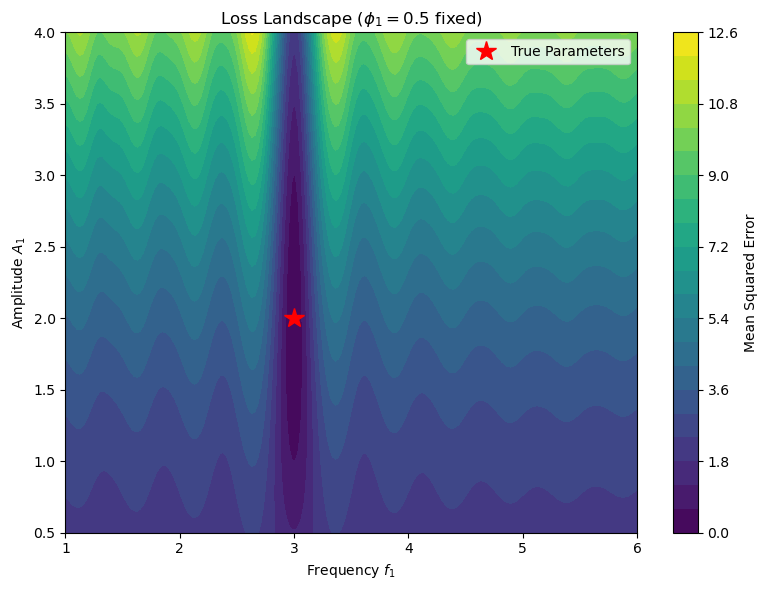

>>> Loss at true params: 0.087880


In [7]:
class SignalFitter:
    def __init__(self, t, y_obs, K):
        # Store time array, observed signal, and number of components
        self.t = t
        self.y_obs = y_obs
        self.K = K
        self.n_params = K * 3
        self.current_loss = None

    def predict(self, params):
        # Reshape flat parameters into K rows of [A, f, phi]
        params = np.array(params).reshape(self.K, 3)

        # Initialize predicted signal
        y_pred = np.zeros_like(self.t)

        # Sum all sinusoidal components
        for A, f, phi in params:
            y_pred += A * np.sin(2 * np.pi * f * self.t + phi)

        return y_pred

    def loss(self, params):
        # Predict signal using the given parameters
        y_pred = self.predict(params)

        # Compute Mean Squared Error
        self.current_loss = np.mean((y_pred - self.y_obs) ** 2)

        return self.current_loss

# Generate noisy observations for Test Case 1
y_obs1 = generate_signal(t, true_params1)

# Create SignalFitter instance
fitter1 = SignalFitter(t, y_obs1, K=1)

# Define parameter ranges
A_vals = np.linspace(0.5, 4.0, 200)
f_vals = np.linspace(1.0, 6.0, 200)
phi_vals = np.linspace(-np.pi, np.pi, 200)

# Initialize loss grid
loss_grid = np.zeros((200, 200))

# Compute MSE for each amplitude-frequency combination
# Keep phase fixed at its true value (0.5)
# You can also fix other parameters or fix 2 at a time
for i, A in enumerate(A_vals):
    for j, f in enumerate(f_vals):
        loss_grid[i, j] = fitter1.loss(np.array([A, f, 0.5]))

# Plot loss landscape
fig, ax = plt.subplots(figsize=(8, 6))

cf = ax.contourf(
    f_vals, A_vals, loss_grid,
    levels=20, cmap='viridis'
)

fig.colorbar(cf, ax=ax, label='Mean Squared Error')

# Mark the true parameters
ax.plot(
    true_params1[0, 1],
    true_params1[0, 0],
    '*', color='red', markersize=15,
    label='True Parameters'
)

ax.set_xlabel('Frequency $f_1$')
ax.set_ylabel('Amplitude $A_1$')
ax.set_title('Loss Landscape ($\\phi_1=0.5$ fixed)')
ax.legend()

plt.tight_layout()
plt.show()

# Print loss at true parameters
print(f">>> Loss at true params: {fitter1.loss(true_params1.flatten()):.6f}")

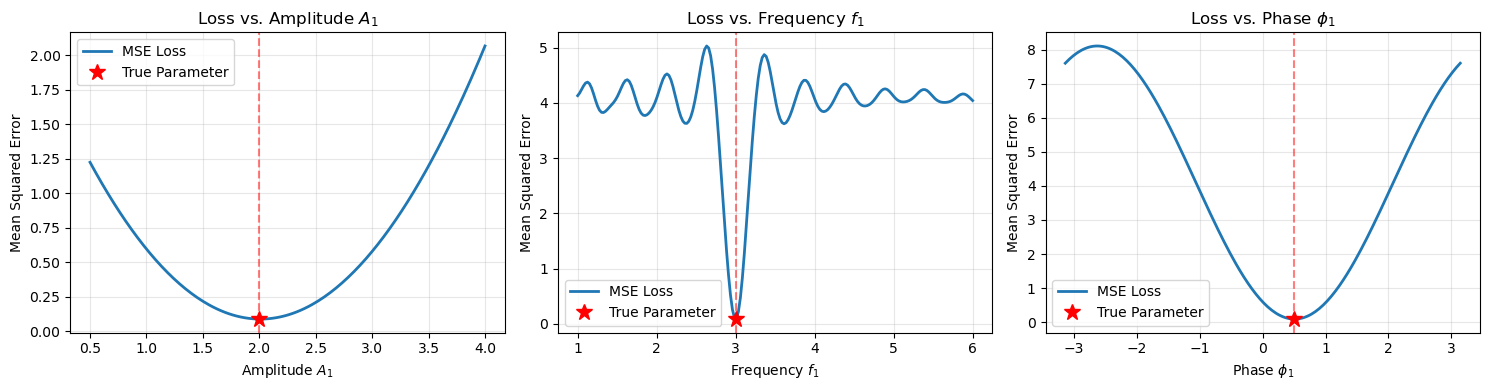

>>> Loss at true params: 0.087880


In [8]:
# Extract true parameters
A_true, f_true, phi_true = true_params1[0]

# Calculate loss while varying one parameter at a time
# The other two parameters remain fixed at their true values
loss_A = [fitter1.loss([A, f_true, phi_true]) for A in A_vals]
loss_f = [fitter1.loss([A_true, f, phi_true]) for f in f_vals]
loss_phi = [fitter1.loss([A_true, f_true, phi]) for phi in phi_vals]

# Compute loss at true parameters
true_loss = fitter1.loss(true_params1.flatten())

# Plot three 1D loss landscapes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

parameter_data = [
    (A_vals, loss_A, A_true, 'Amplitude $A_1$'),
    (f_vals, loss_f, f_true, 'Frequency $f_1$'),
    (phi_vals, loss_phi, phi_true, 'Phase $\\phi_1$')
]

for ax, (values, losses, true_value, label) in zip(axes, parameter_data):
    ax.plot(values, losses, linewidth=2, label='MSE Loss')

    # Mark the true parameter and its corresponding loss
    ax.plot(true_value, true_loss, 'r*', markersize=12,
            label='True Parameter')
    ax.axvline(true_value, color='red', linestyle='--', alpha=0.5)

    ax.set_xlabel(label)
    ax.set_ylabel('Mean Squared Error')
    ax.set_title(f'Loss vs. {label}')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f">>> Loss at true params: {true_loss:.6f}")


## 3b: Numerical Gradients (7.5 Points)

Add a `grad` method to `SignalFitter` that computes the numerical gradient of the loss with respect to all parameters using the central difference formula:

$$\frac{\partial \mathcal{L}}{\partial \theta_i} \approx \frac{\mathcal{L}(\theta_i + h) - \mathcal{L}(\theta_i - h)}{2h}$$

```py
def grad(self, params, h=1e-5):
    #Initialize gradient array (same shape as params)
    #Loop over each parameter dimension i
        #Perturb params positively and negatively in dimension i
        #Compute loss_plus and loss_minus
        #Central difference
    #self.grads
    pass
```

To verify correctness, plot the analytical partial derivative check. That is to say, for Test Case 1, plot the loss as a function of $A_1$ (sweeping over `np.linspace(0.5, 4.0, 200)` with $f_1, \phi_1$ held at their given true values) alongside the numerical gradient (as a tangent line at the true $A_1$). The tangent should visually match the slope of the loss curve.

Also print the gradient at the true parameters:
```py
>>> Gradient at true params: [X.XXXX, X.XXXX, X.XXXX]
```

Feel free to consult the following plotting code:
```py
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(A_sweep, losses_A, label='Loss vs A1')
ax.plot(A_sweep, tangent, '--', color='red', label=f'Tangent at true A1 (slope={dL_dA:.4f})')
ax.axvline(true_flat[0], color='green', linestyle=':', label=f'True A1={true_flat[0]}')
ax.set_xlabel('Amplitude A1'); ax.set_ylabel('MSE Loss')
ax.set_title('Numerical Gradient Tangent Check'); ax.legend()
plt.tight_layout(); plt.show()

print(f"Gradient at true params: {[round(g, 4) for g in grads_true]}")
```

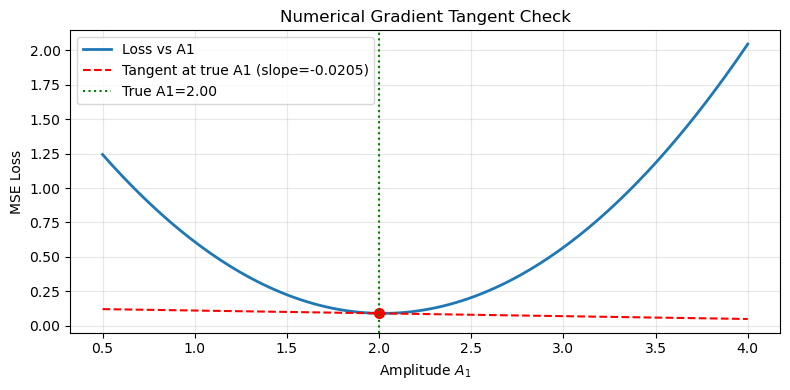

>>> Gradient at true params: [-0.0205  0.1197  0.0252]


In [13]:
class SignalFitter:
    def __init__(self, t, y_obs, K):
        self.t = t
        self.y_obs = y_obs
        self.K = K
        self.n_params = K * 3
        self.current_loss = None
        self.grads = None

    def predict(self, params):
        params = np.array(params).reshape(self.K, 3)

        y_pred = np.zeros_like(self.t)

        for A, f, phi in params:
            y_pred += A * np.sin(2 * np.pi * f * self.t + phi)

        return y_pred

    def loss(self, params):
        y_pred = self.predict(params)
        self.current_loss = np.mean((y_pred - self.y_obs) ** 2)

        return self.current_loss

    def grad(self, params, h=1e-5):
        # Initialize gradient array
        self.grads = np.zeros_like(params, dtype=float)

        # Compute numerical gradient for each parameter
        for i in range(self.n_params):
            params_plus = params.copy()
            params_minus = params.copy()

            params_plus[i] += h
            params_minus[i] -= h

            loss_plus = self.loss(params_plus)
            loss_minus = self.loss(params_minus)

            self.grads[i] = (loss_plus - loss_minus) / (2 * h)

        return self.grads

# Generate noisy observations for Test Case 1
y_obs1 = generate_signal(t, true_params1)

# Create SignalFitter instance
fitter1 = SignalFitter(t, y_obs1, K=1)

# Flatten true parameters
true_flat = true_params1.flatten()

# Compute numerical gradients at true parameters
grads_true = fitter1.grad(true_flat)

# Sweep amplitude while keeping frequency and phase fixed
A_sweep = np.linspace(0.5, 4.0, 200)

losses_A = [
    fitter1.loss([A, true_flat[1], true_flat[2]])
    for A in A_sweep
]

# Calculate tangent line at the true amplitude
A_true = true_flat[0]
loss_true = fitter1.loss(true_flat)
dL_dA = grads_true[0]

tangent = loss_true + dL_dA * (A_sweep - A_true)

# Plot loss and tangent line
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(A_sweep, losses_A, linewidth=2, label='Loss vs A1')

ax.plot(A_sweep, tangent, '--', color='red',
        label=f'Tangent at true A1 (slope={dL_dA:.4f})')

ax.plot(A_true, loss_true, 'ro', markersize=7)
ax.axvline(A_true, color='green', linestyle=':',
           label=f'True A1={A_true:.2f}')

ax.set_xlabel('Amplitude $A_1$')
ax.set_ylabel('MSE Loss')
ax.set_title('Numerical Gradient Tangent Check')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print numerical gradients
print(f">>> Gradient at true params: {np.round(grads_true, 4)}")



### Numerical Gradient Verification

We approximate the gradient of the MSE loss using the central difference method:

$$
\frac{\partial L}{\partial \theta_i}
\approx
\frac{L(\theta_i+h)-L(\theta_i-h)}{2h}
$$

where $h=10^{-5}$ and $\theta=[A_1,f_1,\phi_1]$.

To verify the numerical gradient, we vary $A_1$ while keeping $f_1=3.0$ and $\phi_1=0.5$ fixed.

The tangent line at the true amplitude $A_1=2.0$ is calculated as:

$$
L_{\text{tangent}}(A_1)=
L(2.0)+
\left.\frac{\partial L}{\partial A_1}\right|_{A_1=2.0}
(A_1-2.0)
$$

The tangent should match the local slope of the loss curve at $A_1=2.0$, confirming that the numerical gradient is computed correctly for the amplitude parameter.

Because the observed signal contains Gaussian noise, the gradient at the true parameters may not be exactly zero.


## 3c: Gradient Descent Optimizer (15 Points)

Add the `fit` method to `SignalFitter` to implement gradient descent with ADAM:

```py
def fit(self, n_iterations=3_000, learning_rate=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
	#Seed guesses for frequency with fft results
	dt = self.t[1]-self.t[0]
	freqs = np.fft.rfftfreq(len(self.t), d=dt)
	fft_mag = np.abs(np.fft.rfft(self.y_obs))
	peak_indices = np.argsort(fft_mag[1:])[-self.K:] + 1
	f_inits = np.sort(freqs[peak_indices])

	params = np.empty(self.n_params)
	for k in range(self.K):
		params[k*3] = np.random.uniform(0.5, 3.0)
		params[k*3+1] = f_inits[k]
		params[k*3+2] = np.random.uniform(0, 2*np.pi)

    #Initialize velocity v to zeros
    #Iteration loop:
        #Compute gradient
        #Run ADAM
        #Clip params to reasonable bounds: A in [0.01, 10], f in [0.1, 20], phi in [0, 2*pi]
        #Track current loss
    #Store best result

    #self.best_params, self.best_loss, self.loss_history (list of loss per iteration)
    pass
```

Run `fit` on all three test cases with default parameters. For each:
1. Plot the loss curve (log scale y-axis) over iterations.
2. Plot the observed signal, the true signal (noiseless), and the fitted signal on one figure.
3. Print the final parameters and loss:
```py
>>> [Case X] Final Loss: X.XXXXXX
>>> [Case X] Fitted params: [[A1, f1, phi1], [A2, f2, phi2], ...]
```

Feel free to consult the following plotting code:
```py
#Run on all three test cases
test_cases = [(true_params1, y_obs1, 1),
              (true_params2, generate_signal(t, true_params2), 2),
              (true_params3, generate_signal(t, true_params3), 3)]

for true_p, y_obs, case_num in test_cases:
    K = len(true_p)
    fitter = SignalFitter(t, y_obs, K=K)
    fitter.fit()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].semilogy(fitter.loss_history)
    axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Loss (log scale)')
    axes[0].set_title(f'Case {case_num} - Loss Curve')

    y_true = generate_signal(t, true_p, noise_std=0)
    y_fitted = fitter.predict(fitter.best_params)
    axes[1].plot(t, y_obs, alpha=0.4, label='Observed (noisy)')
    axes[1].plot(t, y_true, linewidth=2, label='True (noiseless)')
    axes[1].plot(t, y_fitted, linewidth=2, linestyle='--', label='Fitted')
    axes[1].set_xlabel('Time'); axes[1].set_ylabel('Amplitude')
    axes[1].set_title(f'Case {case_num} - Signal Fit'); axes[1].legend()
    plt.tight_layout(); plt.show()

    fitted_rounded = fitter.best_params.reshape(K, 3).round(4).tolist()
    print(f"[Case {case_num}] Final Loss: {fitter.best_loss:.6f}")
    print(f"[Case {case_num}] Fitted params: {fitted_rounded}")
```

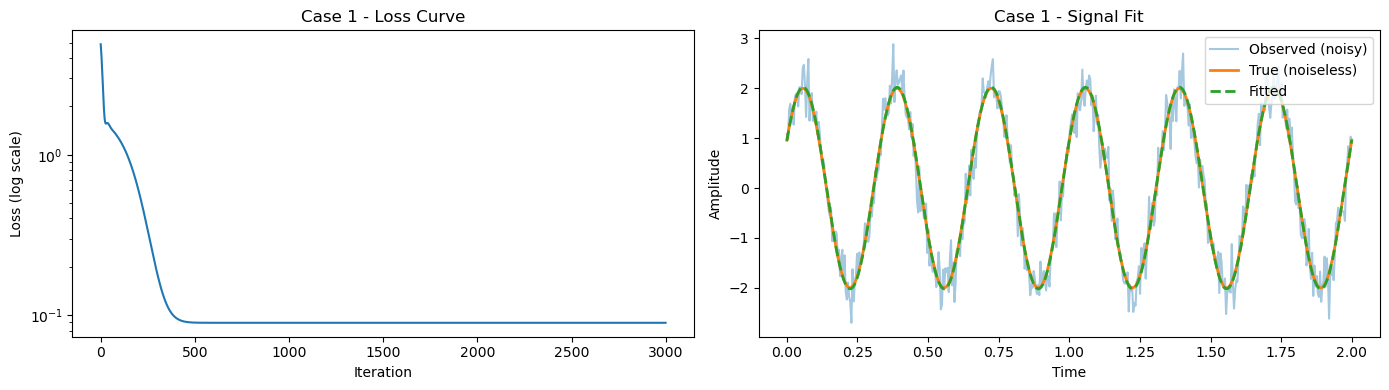

>>> [Case 1] Final Loss: 0.089395
>>> [Case 1] Fitted params: [[2.0207, 3.0008, 0.4884]]


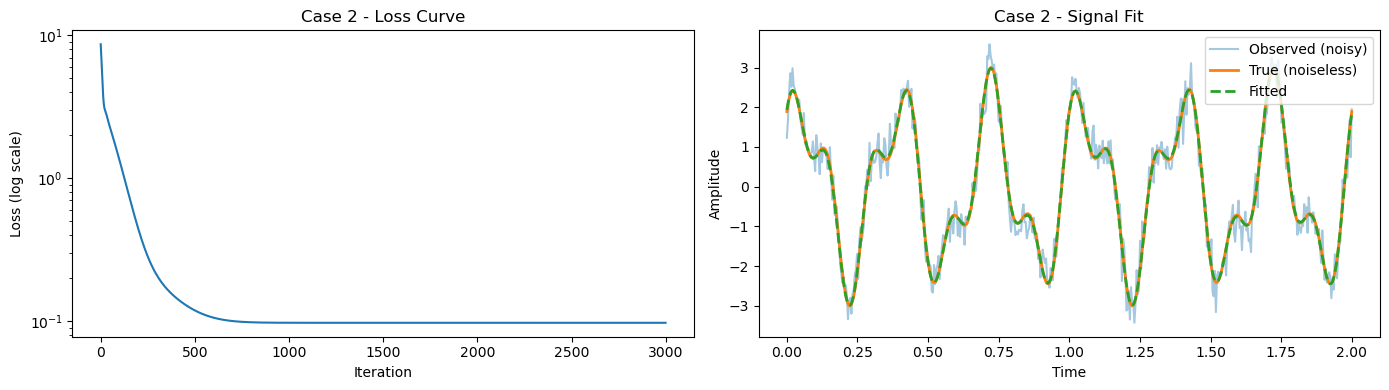

>>> [Case 2] Final Loss: 0.097169
>>> [Case 2] Fitted params: [[2.013, 2.9965, 0.5314], [0.9734, 6.9976, 1.2228]]


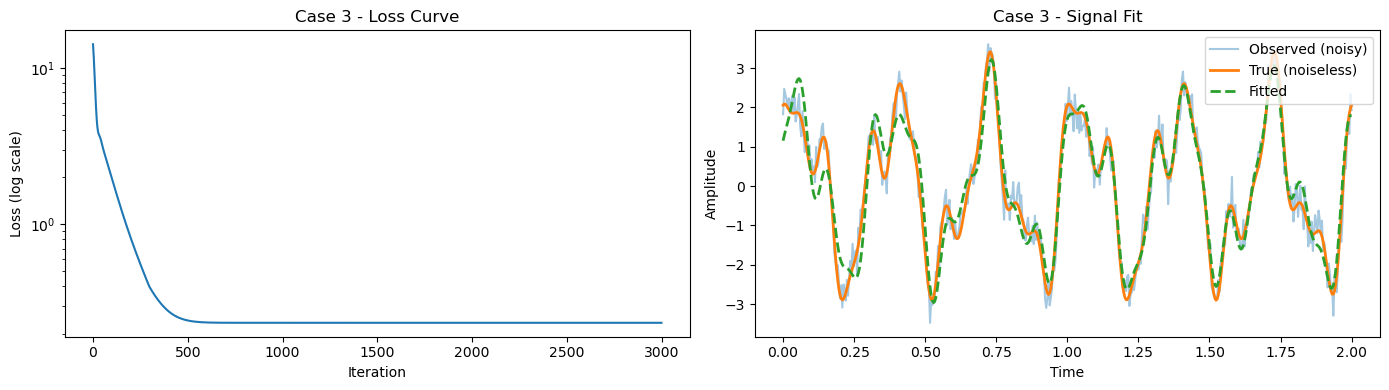

>>> [Case 3] Final Loss: 0.234289
>>> [Case 3] Fitted params: [[1.945, 2.9926, 0.5224], [0.8266, 7.1418, 6.2832], [0.4795, 12.0026, 2.7474]]


In [14]:
class SignalFitter:
    def __init__(self, t, y_obs, K):
        self.t = t
        self.y_obs = y_obs
        self.K = K
        self.n_params = K * 3
        self.current_loss = None
        self.grads = None

    def predict(self, params):
        params = np.array(params).reshape(self.K, 3)

        y_pred = np.zeros_like(self.t)

        for A, f, phi in params:
            y_pred += A * np.sin(2 * np.pi * f * self.t + phi)

        return y_pred

    def loss(self, params):
        y_pred = self.predict(params)
        self.current_loss = np.mean((y_pred - self.y_obs) ** 2)

        return self.current_loss

    def grad(self, params, h=1e-5):
        # Initialize gradient array
        self.grads = np.zeros_like(params, dtype=float)

        # Compute numerical gradient for each parameter
        for i in range(self.n_params):
            params_plus = params.copy()
            params_minus = params.copy()

            params_plus[i] += h
            params_minus[i] -= h

            loss_plus = self.loss(params_plus)
            loss_minus = self.loss(params_minus)

            self.grads[i] = (loss_plus - loss_minus) / (2 * h)

        return self.grads

    def fit(self, n_iterations=3_000, learning_rate=0.01,
            beta1=0.9, beta2=0.999, eps=1e-8):

        # Step 1: Initialize frequencies using FFT
        dt = self.t[1] - self.t[0]
        freqs = np.fft.rfftfreq(len(self.t), d=dt)
        fft_mag = np.abs(np.fft.rfft(self.y_obs))

        peak_indices = np.argsort(fft_mag[1:])[-self.K:] + 1
        f_inits = np.sort(freqs[peak_indices])

        # Initialize amplitudes, frequencies, and phases
        params = np.empty(self.n_params)

        for k in range(self.K):
            params[k*3] = np.random.uniform(0.5, 3.0)
            params[k*3+1] = f_inits[k]
            params[k*3+2] = np.random.uniform(0, 2*np.pi)

        # Step 2: Initialize ADAM first and second moments
        v = np.zeros(self.n_params)
        s = np.zeros(self.n_params)

        # Track training loss and best parameters
        self.loss_history = []
        self.best_params = params.copy()
        self.best_loss = self.loss(params)

        # Step 3: Gradient descent with ADAM
        for i in range(1, n_iterations + 1):

            # Compute numerical gradient
            grads = self.grad(params)

            # Update first moment (momentum)
            v = beta1 * v + (1 - beta1) * grads

            # Update second moment (squared gradients)
            s = beta2 * s + (1 - beta2) * (grads ** 2)

            # Bias correction
            v_hat = v / (1 - beta1 ** i)
            s_hat = s / (1 - beta2 ** i)

            # ADAM parameter update
            params -= learning_rate * v_hat / (np.sqrt(s_hat) + eps)

            # Step 4: Clip parameters to valid ranges
            params[0::3] = np.clip(params[0::3], 0.01, 10)
            params[1::3] = np.clip(params[1::3], 0.1, 20)
            params[2::3] = np.clip(params[2::3], 0, 2*np.pi)

            # Step 5: Calculate and record current loss
            current_loss = self.loss(params)
            self.loss_history.append(current_loss)

            # Save best parameters found
            if current_loss < self.best_loss:
                self.best_loss = current_loss
                self.best_params = params.copy()

        return self.best_params


# Generate test signals
test_cases = [
    (true_params1, y_obs1, 1),
    (true_params2, generate_signal(t, true_params2), 2),
    (true_params3, generate_signal(t, true_params3), 3)
]

# Run gradient descent with ADAM on each test case
for true_p, y_obs, case_num in test_cases:

    K = len(true_p)

    # Initialize and train the fitter
    fitter = SignalFitter(t, y_obs, K=K)
    fitter.fit()

    # Create two plots for each test case
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Plot 1: Loss over iterations
    axes[0].semilogy(fitter.loss_history)
    axes[0].set_xlabel('Iteration')
    axes[0].set_ylabel('Loss (log scale)')
    axes[0].set_title(f'Case {case_num} - Loss Curve')

    # Plot 2: Compare observed, true, and fitted signals
    y_true = generate_signal(t, true_p, noise_std=0)
    y_fitted = fitter.predict(fitter.best_params)

    axes[1].plot(t, y_obs, alpha=0.4, label='Observed (noisy)')
    axes[1].plot(t, y_true, linewidth=2, label='True (noiseless)')
    axes[1].plot(t, y_fitted, linewidth=2,
                 linestyle='--', label='Fitted')

    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('Amplitude')
    axes[1].set_title(f'Case {case_num} - Signal Fit')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # Print final results
    fitted_rounded = fitter.best_params.reshape(K, 3).round(4).tolist()

    print(f">>> [Case {case_num}] Final Loss: {fitter.best_loss:.6f}")
    print(f">>> [Case {case_num}] Fitted params: {fitted_rounded}")


### Gradient Descent with ADAM

We use the ADAM optimizer to minimize the Mean Squared Error between the observed signal and the predicted sum of sinusoids.

**1. Initialization:** We use the Fast Fourier Transform (FFT) to estimate the initial frequencies. Amplitudes and phases are initialized randomly.

**2. Numerical gradients:** At each iteration, we calculate the gradient of the loss with respect to every amplitude, frequency, and phase using central differences.

**3. ADAM optimization:** ADAM maintains exponentially weighted averages of gradients and squared gradients:

$$
v_t=\beta_1v_{t-1}+(1-\beta_1)g_t
$$

$$
s_t=\beta_2s_{t-1}+(1-\beta_2)g_t^2
$$

After bias correction, the parameters are updated using:

$$
\theta_t=\theta_{t-1}
-\eta\frac{\hat v_t}{\sqrt{\hat s_t}+\epsilon}
$$

We use a learning rate of 0.01 and train for 3,000 iterations.

**4. Evaluation:** We compare the fitted signal with the observed and true signals and visualize the MSE loss over training.

The loss should generally decrease as optimization progresses. However, recovering parameters becomes more challenging as the number of sinusoidal components increases because the loss landscape contains multiple local minima.

Since the observations contain Gaussian noise with standard deviation 0.3, a successful fit should generally achieve an MSE near 0.09, although the exact value varies with the sampled noise.


## 3d: Sensitivity Analysis (7.5 Points)

Investigate how sensitive the optimizer is to the learning rate and noise scale on Test Case 2.

For learning rates in `[0.0001, 0.001, 0.005, 0.01, 0.025, 0.05]` and beta1 in `[0.5, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99]`:
- Run `fit` with `n_iterations=1_000` for each combination.
- Record the final best loss.

Produce a heatmap (using `plt.imshow` or `plt.pcolormesh`) of the final loss across the grid of (learning_rate x beta1). Use a log color scale (`norm=matplotlib.colors.LogNorm()`). Import `matplotlib.colors` if needed.

Print the best combination found:
```py
>>> Best: lr=X.XXXX, beta1=X.XXXX -> Loss: X.XXXXXX
```

Feel free to consult the following plotting code:
```py
import matplotlib.colors

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.pcolormesh(loss_grid, norm=matplotlib.colors.LogNorm(), cmap='viridis')
fig.colorbar(im, label='Final Loss (log scale)')

for i in range(len(learning_rates)):
    for j in range(len(beta1s)):
        ax.text(j+0.5, i+0.5, f"{loss_grid[i,j]:.2e}",
                ha='center', va='center', color='red', fontsize=10, fontweight='bold')

ax.set_xticks(np.arange(len(beta1s))+0.5); ax.set_xticklabels(beta1s)
ax.set_yticks(np.arange(len(learning_rates))+0.5); ax.set_yticklabels(learning_rates)
ax.set_xlabel('Beta 1'); ax.set_ylabel('Learning Rate')
ax.set_title('Sensitivity Analysis: Final Loss (Test Case 2)')
plt.tight_layout(); plt.show()

best_idx = np.unravel_index(np.argmin(loss_grid), loss_grid.shape)
best_lr = learning_rates[best_idx[0]]
best_nr = beta1s[best_idx[1]]
print(f"Best: lr={best_lr}, beta1={best_nr} -> Loss: {loss_grid[best_idx]:.6f}")
```

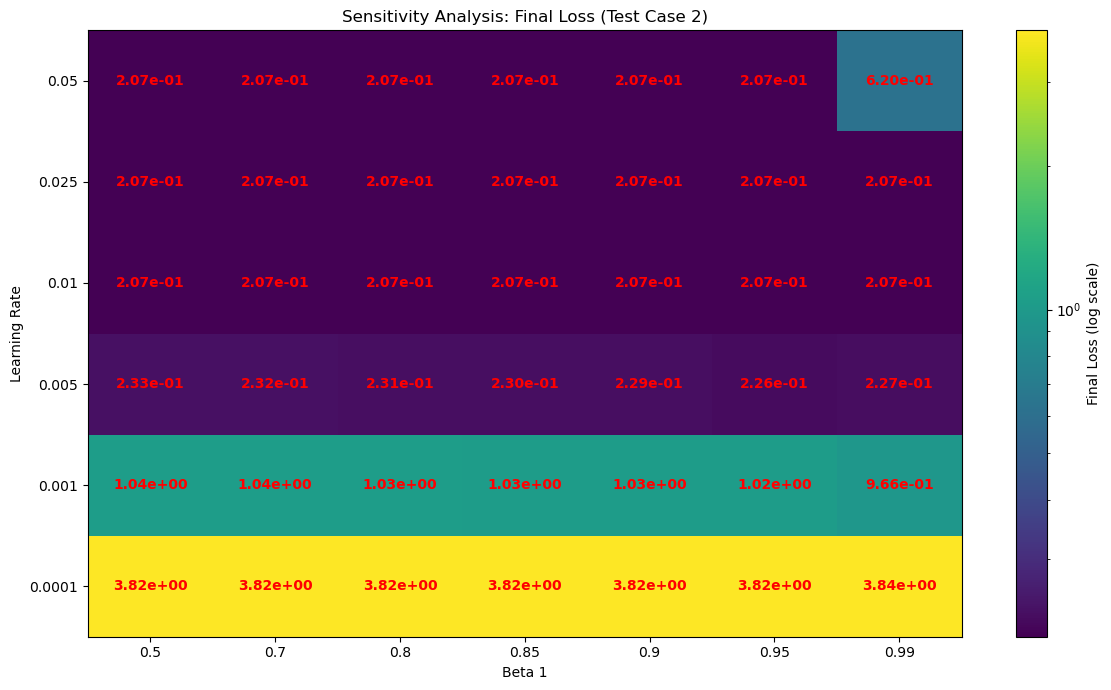

>>> Best: lr=0.0500, beta1=0.7000 -> Loss: 0.206647


In [15]:
import matplotlib.colors

# Define hyperparameter values
learning_rates = [0.0001, 0.001, 0.005, 0.01, 0.025, 0.05]
beta1s = [0.5, 0.7, 0.8, 0.85, 0.9, 0.95, 0.99]

# Use the same observed signal for all experiments
y_obs2 = generate_signal(t, true_params2)

# Initialize loss grid
loss_grid = np.zeros((len(learning_rates), len(beta1s)))

# Test all hyperparameter combinations
for i, lr in enumerate(learning_rates):
    for j, beta1 in enumerate(beta1s):

        # Use the same random initialization for fair comparison
        np.random.seed(42)

        # Create a new fitter for each experiment
        fitter = SignalFitter(t, y_obs2, K=2)

        # Train with the current hyperparameters
        fitter.fit(
            n_iterations=1_000,
            learning_rate=lr,
            beta1=beta1
        )

        # Record the best loss achieved
        loss_grid[i, j] = fitter.best_loss

# Plot heatmap
fig, ax = plt.subplots(figsize=(12, 7))

im = ax.pcolormesh(
    loss_grid,
    norm=matplotlib.colors.LogNorm(),
    cmap='viridis'
)

fig.colorbar(im, ax=ax, label='Final Loss (log scale)')

# Annotate each cell with its loss
for i in range(len(learning_rates)):
    for j in range(len(beta1s)):
        ax.text(
            j + 0.5, i + 0.5,
            f"{loss_grid[i, j]:.2e}",
            ha='center',
            va='center',
            color='red',
            fontsize=10,
            fontweight='bold'
        )

# Set axis labels
ax.set_xticks(np.arange(len(beta1s)) + 0.5)
ax.set_xticklabels(beta1s)

ax.set_yticks(np.arange(len(learning_rates)) + 0.5)
ax.set_yticklabels(learning_rates)

ax.set_xlabel('Beta 1')
ax.set_ylabel('Learning Rate')
ax.set_title('Sensitivity Analysis: Final Loss (Test Case 2)')

plt.tight_layout()
plt.show()

# Find the best hyperparameter combination
best_idx = np.unravel_index(np.argmin(loss_grid), loss_grid.shape)

best_lr = learning_rates[best_idx[0]]
best_nr = beta1s[best_idx[1]]

print(f">>> Best: lr={best_lr:.4f}, beta1={best_nr:.4f} "
      f"-> Loss: {loss_grid[best_idx]:.6f}")



### Sensitivity Analysis of ADAM Hyperparameters

We investigate how the learning rate $\eta$ and momentum parameter $\beta_1$ affect ADAM's optimization performance on Test Case 2.

We evaluate 6 learning rates and 7 values of $\beta_1$, resulting in 42 experiments. Each experiment runs for 1,000 iterations using the same noisy observations and random initialization.

- **Learning rate ($\eta$):** Controls the magnitude of parameter updates. Small learning rates may lead to slow convergence, while large learning rates can cause unstable optimization.
- **Momentum parameter ($\beta_1$):** Controls the exponential moving average of past gradients. Larger values provide stronger smoothing of gradient updates but may respond more slowly to changes in gradient direction.

The heatmap shows the lowest MSE achieved during training for each hyperparameter combination, using a logarithmic color scale.

Lower loss values indicate better fitting performance. The best combination is selected as the one achieving the minimum loss across all 42 experiments.

Because the loss function is nonconvex, the best hyperparameters may depend on the initial parameters and observed noise.
